# A14 — Keypoint Confidence Score Prediction for Ugly Recording Detection

This notebook implements the **keypoint confidence score** part of Lab Assignment 14.

The final A14 solution should use both:

- pose confidence score
- keypoint confidence score

In this notebook, we focus only on the **keypoint confidence score**.

The goal is to predict whether a recording is likely to be useful or ugly early in the recording, before the exercise starts.

The target is an objective whole-recording keypoint confidence score calculated from all MoveNet keypoint scores in the recording.

The input is only the first fixed-size sequence of `c` frames.

The notebook follows the Deep Learning steps:

1. Load and prepare movement data
2. Define Deep Learning networks
3. Compile the model
4. Split training and testing sets with cross-validation
5. Train the model
6. Evaluate predictions
7. Use and log the model with an MLflow pyfunc wrapper

This notebook is designed so the model can easily be retrained and reused in the practical application pipeline.

## Imports, settings, paths

In [12]:
from pathlib import Path
import os
import random
import warnings
import json
import copy
import time
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
import mlflow.pyfunc
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# A14 setup
SEQ_LEN = 10
N_SPLITS = 10
VALIDATION_SPLIT = 0.10

# Training defaults
EPOCHS = 120
PATIENCE = 15
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

# Practical rejection thresholds.
# These can be adjusted after looking at the real data distribution.
KEYPOINT_CONFIDENCE_ACCEPT_THRESHOLD = 0.70
KEYPOINT_CONFIDENCE_WARN_THRESHOLD = 0.60

# Candidate locations for MoveNet CSV files.
# The notebook will use the first folder that exists and contains CSV files.
MOVENET_DIR_CANDIDATES = [
    Path("../../data/processed/Good_vs_Bad_movenet/csv_output"),
    Path("../../data/processed/movenet/csv_output"),
    Path("../../data/processed/MoveNet/csv_output"),
    Path("../../data/raw/movenet/csv_output"),
    Path("../../data/processed/Good_vs_Bad_movenet/csv_output"),
]

MOVENET_DIR = None
for candidate in MOVENET_DIR_CANDIDATES:
    if candidate.exists() and len(list(candidate.glob("*.csv"))) > 0:
        MOVENET_DIR = candidate
        break

if MOVENET_DIR is None:
    raise FileNotFoundError(
        "Could not find a MoveNet CSV directory. Update MOVENET_DIR_CANDIDATES or set MOVENET_DIR manually."
    )

# Output locations
output_dir = Path("reporting/results")
artifact_dir = Path("reporting/artifacts")
output_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Using MoveNet directory:", MOVENET_DIR)
print("Number of CSV files:", len(list(MOVENET_DIR.glob("*.csv"))))

Device: cuda
Using MoveNet directory: ..\..\data\processed\Good_vs_Bad_movenet\csv_output
Number of CSV files: 114


## MLflow setup

In [13]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A14_keypoint_confidence_ugly_recording"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A14_keypoint_confidence_ugly_recording


## Objective labeling criteria for the keypoint-confidence part

For this notebook, the label is not manually guessed. It is calculated objectively from MoveNet keypoint confidence scores.

Each keypoint confidence score is between `0.0` and `1.0`.

For one whole recording, the target is:

`target_keypoint_confidence = mean confidence across all selected keypoints and all frames`

This gives a whole-recording confidence estimate.

The practical interpretation is:

- high score: MoveNet is confident about the detected keypoints
- low score: the recording is likely problematic due to poor light, contrast, clothing, background, occlusion, or unstable detection

The final group submission should also include the subjective good/bad/ugly manual labels and the group criteria for those labels.  
This notebook creates an objective keypoint-confidence label table that can be shared as part of the submission.

In [14]:
FRAME_COL_CANDIDATES = [
    "frame_index",
    "frame",
    "frame_id",
    "Frame",
    "FrameID",
    "FrameNo",
    "frame_no",
    "image_id",
    "image_index",
]

MOVENET_TO_ASSIGNMENT = {
    "nose": "head",
    "left_shoulder": "left_shoulder",
    "left_elbow": "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow": "right_elbow",
    "left_wrist": "left_hand",
    "right_wrist": "right_hand",
    "left_hip": "left_hip",
    "right_hip": "right_hip",
    "left_knee": "left_knee",
    "right_knee": "right_knee",
    "left_ankle": "left_foot",
    "right_ankle": "right_foot",
}

JOINTS_13 = list(MOVENET_TO_ASSIGNMENT.values())

COORD_COLS = []
SCORE_COLS = []

for joint in JOINTS_13:
    COORD_COLS.extend([f"{joint}_x", f"{joint}_y"])
    SCORE_COLS.append(f"{joint}_score")


def strip_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def find_frame_col(df: pd.DataFrame) -> str:
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def stem_base(csv_path: Path) -> str:
    return csv_path.stem


def load_movenet_as_assignment_df(csv_path: str | Path) -> pd.DataFrame:
    """
    Converts a MoveNet CSV to the assignment's 13-joint format.

    Expected raw MoveNet columns may include:
    nose_x, nose_y, nose_score,
    left_shoulder_x, left_shoulder_y, left_shoulder_score,
    ...

    Output:
    frame_index,
    head_x, head_y, head_score,
    left_shoulder_x, left_shoulder_y, left_shoulder_score,
    ...
    """
    df = pd.read_csv(csv_path)
    df = strip_columns(df)

    frame_col = find_frame_col(df)

    out = pd.DataFrame()
    out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

    if "timestamp_ms" in df.columns:
        out["timestamp_ms"] = df["timestamp_ms"]

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"

            if src in df.columns:
                out[dst] = pd.to_numeric(df[src], errors="coerce")
            elif dst in df.columns:
                out[dst] = pd.to_numeric(df[dst], errors="coerce")
            else:
                raise ValueError(
                    f"Missing column '{src}' or '{dst}' in {csv_path}. "
                    "The keypoint confidence model needs x, y, and score columns."
                )

    out = out.sort_values("frame_index").reset_index(drop=True)
    return out

## Load recordings and calculate objective keypoint-confidence labels

In [15]:
def calculate_recording_keypoint_confidence(df: pd.DataFrame) -> dict:
    """
    Calculates objective whole-recording confidence labels from keypoint scores.

    Main regression target:
    - mean_keypoint_confidence

    Extra practical diagnostics:
    - min_keypoint_confidence
    - p10_keypoint_confidence
    - fraction_keypoints_below_030
    - fraction_frames_with_any_keypoint_below_030
    """
    scores = df[SCORE_COLS].to_numpy(dtype=np.float32)

    mean_score = float(np.nanmean(scores))
    min_score = float(np.nanmin(scores))
    p10_score = float(np.nanpercentile(scores, 10))

    below_030 = scores < 0.30
    fraction_keypoints_below_030 = float(np.nanmean(below_030))

    frame_has_low_keypoint = np.any(below_030, axis=1)
    fraction_frames_with_any_keypoint_below_030 = float(np.mean(frame_has_low_keypoint))

    return {
        "target_keypoint_confidence": mean_score,
        "min_keypoint_confidence": min_score,
        "p10_keypoint_confidence": p10_score,
        "fraction_keypoints_below_030": fraction_keypoints_below_030,
        "fraction_frames_with_any_keypoint_below_030": fraction_frames_with_any_keypoint_below_030,
    }


def load_all_recordings(movenet_dir: Path) -> tuple[pd.DataFrame, dict[str, pd.DataFrame]]:
    rows = []
    sequence_dfs = {}

    csv_files = sorted(movenet_dir.glob("*.csv"))
    print("Found MoveNet CSV files:", len(csv_files))

    for csv_path in csv_files:
        sequence_id = stem_base(csv_path)

        try:
            df = load_movenet_as_assignment_df(csv_path)

            # Remove rows with missing keypoint scores.
            df = df.dropna(subset=SCORE_COLS).copy()

            if len(df) < SEQ_LEN:
                rows.append({
                    "sequence_id": sequence_id,
                    "path": str(csv_path),
                    "kept": False,
                    "reason": "too_short",
                    "n_frames": len(df),
                })
                continue

            label_info = calculate_recording_keypoint_confidence(df)

            sequence_dfs[sequence_id] = df

            rows.append({
                "sequence_id": sequence_id,
                "path": str(csv_path),
                "kept": True,
                "reason": "ok",
                "n_frames": len(df),
                **label_info,
            })

        except Exception as e:
            rows.append({
                "sequence_id": sequence_id,
                "path": str(csv_path),
                "kept": False,
                "reason": f"error: {e}",
                "n_frames": np.nan,
            })

    catalog_df = pd.DataFrame(rows)
    return catalog_df, sequence_dfs


catalog_df, sequence_dfs = load_all_recordings(MOVENET_DIR)

catalog_path = output_dir / "a14_keypoint_confidence_labels.csv"
catalog_df.to_csv(catalog_path, index=False)

display(catalog_df.head())
print("Saved objective keypoint-confidence labels to:", catalog_path)

kept_catalog_df = catalog_df[catalog_df["kept"]].copy().reset_index(drop=True)

print("Kept recordings:", len(kept_catalog_df))
print("Target summary:")
display(kept_catalog_df["target_keypoint_confidence"].describe())

Found MoveNet CSV files: 114


,sequence_id,path,kept,reason,n_frames,target_keypoint_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030
0,A1,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,229,0.589341,0.1516,0.41990,0.012429,0.148472
1,G01,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,254,0.546313,0.1342,0.36831,0.039976,0.401575
2,G02,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,314,0.554782,0.0511,0.37742,0.050710,0.423567
3,G03,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,250,0.547615,0.0435,0.35049,0.063692,0.420000
4,G04,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,219,0.493673,0.0232,0.21594,0.154197,0.666667


Saved objective keypoint-confidence labels to: reporting\results\a14_keypoint_confidence_labels.csv
Kept recordings: 114
Target summary:


count    114.000000
mean       0.518529
std        0.027294
min        0.417067
25%        0.505822
50%        0.521612
75%        0.536848
max        0.589341
Name: target_keypoint_confidence, dtype: float64

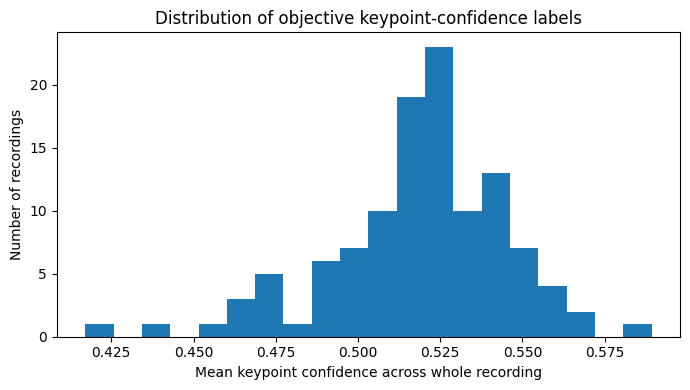

Saved: reporting\results\a14_keypoint_confidence_label_distribution.png


In [16]:
plt.figure(figsize=(7, 4))
plt.hist(kept_catalog_df["target_keypoint_confidence"], bins=20)
plt.title("Distribution of objective keypoint-confidence labels")
plt.xlabel("Mean keypoint confidence across whole recording")
plt.ylabel("Number of recordings")
plt.tight_layout()

hist_path = output_dir / "a14_keypoint_confidence_label_distribution.png"
plt.savefig(hist_path, dpi=150)
plt.show()

print("Saved:", hist_path)

## Feature preparation

The predictor is only allowed to look at the beginning of the recording.

This matches the practical goal: reject or warn about ugly recordings early, before the full exercise is processed.

For each recording:

1. Take the first `c` frames.
2. Use keypoint confidence scores as features.
3. Optionally include normalized keypoint coordinates.
4. Flatten the fixed-size sequence for a small Dense regression model.

The target remains the whole-recording mean keypoint confidence score.

In [17]:
def take_first_frames(df: pd.DataFrame, seq_len: int) -> pd.DataFrame:
    if len(df) < seq_len:
        raise ValueError(f"Sequence has {len(df)} frames, but seq_len={seq_len}.")
    return df.iloc[:seq_len].copy().reset_index(drop=True)


def fit_feature_scaler(
    sequence_ids: list[str],
    sequence_dfs: dict[str, pd.DataFrame],
    feature_cols: list[str],
) -> MinMaxScaler:
    rows = []

    for sequence_id in sequence_ids:
        df = sequence_dfs[sequence_id]
        first_df = take_first_frames(df, SEQ_LEN)
        rows.append(first_df[feature_cols])

    train_feature_df = pd.concat(rows, ignore_index=True)

    scaler = MinMaxScaler()
    scaler.fit(train_feature_df)

    return scaler


def get_feature_columns(feature_set: str) -> list[str]:
    if feature_set == "keypoint_scores":
        return SCORE_COLS

    if feature_set == "coords_keypoint_scores":
        return COORD_COLS + SCORE_COLS

    raise ValueError(f"Unknown feature_set: {feature_set}")


def sequence_to_vector(
    df: pd.DataFrame,
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
) -> np.ndarray:
    feature_cols = get_feature_columns(feature_set)

    first_df = take_first_frames(df, seq_len)
    values_df = first_df[feature_cols].copy()

    values = scaler.transform(values_df)
    return values.astype(np.float32).reshape(-1)


def build_xy_for_sequence_ids(
    sequence_ids: list[str],
    sequence_dfs: dict[str, pd.DataFrame],
    labels_lookup: dict[str, float],
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
) -> tuple[np.ndarray, np.ndarray, list[str]]:
    X_rows = []
    y_rows = []
    ids = []

    for sequence_id in sequence_ids:
        x_vec = sequence_to_vector(
            df=sequence_dfs[sequence_id],
            scaler=scaler,
            seq_len=seq_len,
            feature_set=feature_set,
        )

        X_rows.append(x_vec)
        y_rows.append(labels_lookup[sequence_id])
        ids.append(sequence_id)

    X = np.vstack(X_rows).astype(np.float32)
    y = np.array(y_rows, dtype=np.float32)

    return X, y, ids

## Dataset, model, training helpers

In [18]:
class KeypointConfidenceDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class TinyDenseKeypointConfidenceRegressor(nn.Module):
    """
    Small Dense model for online decision capability.

    Output is restricted to [0, 1] with sigmoid because the target confidence score is in [0, 1].
    """
    def __init__(
        self,
        input_dim: int,
        hidden_dims: tuple[int, ...] = (16, 8),
        dropout: float = 0.05,
    ):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        raw = self.network(x).squeeze(-1)
        return torch.sigmoid(raw)


def count_trainable_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def estimate_dense_macs(input_dim: int, hidden_dims: tuple[int, ...]) -> int:
    """
    Approximate multiply-accumulate operations for one forward pass.
    This is useful for discussing online decision capability.
    """
    dims = [input_dim] + list(hidden_dims) + [1]
    return int(sum(dims[i] * dims[i + 1] for i in range(len(dims) - 1)))


def make_loader(
    X: np.ndarray,
    y: np.ndarray,
    batch_size: int,
    shuffle: bool,
) -> DataLoader:
    dataset = KeypointConfidenceDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )


def evaluate_regression_model(
    model: nn.Module,
    loader: DataLoader,
) -> dict:
    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)

            preds = model(X_batch).detach().cpu().numpy()

            all_pred.extend(preds.tolist())
            all_true.extend(y_batch.numpy().tolist())

    y_true = np.array(all_true)
    y_pred = np.array(all_pred)

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))

    try:
        r2 = r2_score(y_true, y_pred)
    except Exception:
        r2 = np.nan

    return {
        "mae": float(mae),
        "mse": float(mse),
        "rmse": float(rmse),
        "r2": float(r2),
        "y_true": y_true,
        "y_pred": y_pred,
    }


def train_one_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    learning_rate: float,
    epochs: int,
    patience: int,
):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    best_epoch = 0
    epochs_without_improvement = 0

    history_rows = []

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            preds = model(X_batch)
            loss = criterion(preds, y_batch)

            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                preds = model(X_batch)
                loss = criterion(preds, y_batch)

                val_losses.append(loss.item())

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))

        history_rows.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)

    history_df = pd.DataFrame(history_rows)

    summary = {
        "best_val_loss": float(best_val_loss),
        "best_epoch": int(best_epoch),
        "epochs_ran": int(len(history_df)),
    }

    return model, history_df, summary

## Prepare sequence IDs and cross-validation folds

In [19]:
sequence_ids_all = kept_catalog_df["sequence_id"].tolist()

labels_lookup = dict(
    zip(
        kept_catalog_df["sequence_id"],
        kept_catalog_df["target_keypoint_confidence"],
    )
)

n_splits = min(N_SPLITS, len(sequence_ids_all))

if n_splits < 2:
    raise RuntimeError("Need at least two kept recordings for train/test evaluation.")

cv_splitter = KFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=RANDOM_SEED,
)

cv_splits = list(cv_splitter.split(sequence_ids_all))

print("Number of kept recordings:", len(sequence_ids_all))
print("Number of CV folds:", len(cv_splits))

Number of kept recordings: 114
Number of CV folds: 10


## Cross-validation experiment function

In [20]:
def make_train_val_split(
    train_val_sequence_ids: list[str],
    validation_split: float,
    random_state: int,
) -> tuple[list[str], list[str]]:
    train_ids, val_ids = train_test_split(
        train_val_sequence_ids,
        test_size=validation_split,
        random_state=random_state,
    )

    return list(train_ids), list(val_ids)


def run_cv_experiment(
    config: dict,
    run_name: str,
    log_to_mlflow: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    fold_rows = []
    history_rows = []

    with mlflow.start_run(run_name=run_name) if log_to_mlflow else nullcontext():
        feature_cols = get_feature_columns(config["feature_set"])

        if log_to_mlflow:
            mlflow.log_param("task", "ugly_recording_keypoint_confidence_regression")
            mlflow.log_param("input_type", "MoveNet_keypoint_scores")
            mlflow.log_param("model_family", "TinyDense")
            mlflow.log_param("target", "mean_keypoint_confidence_whole_recording")
            mlflow.log_param("seq_len", config["seq_len"])
            mlflow.log_param("feature_set", config["feature_set"])
            mlflow.log_param("hidden_dims", str(config["hidden_dims"]))
            mlflow.log_param("dropout", config["dropout"])
            mlflow.log_param("batch_size", config["batch_size"])
            mlflow.log_param("learning_rate", config["learning_rate"])
            mlflow.log_param("epochs", config["epochs"])
            mlflow.log_param("patience", config["patience"])
            mlflow.log_param("n_recordings", len(sequence_ids_all))
            mlflow.log_param("online_decision", True)
            mlflow.log_param("uses_only_first_frames", True)

        for fold_idx, (train_val_idx, test_idx) in enumerate(cv_splits, start=1):
            train_val_ids = [sequence_ids_all[i] for i in train_val_idx]
            test_ids = [sequence_ids_all[i] for i in test_idx]

            train_ids, val_ids = make_train_val_split(
                train_val_sequence_ids=train_val_ids,
                validation_split=VALIDATION_SPLIT,
                random_state=RANDOM_SEED + fold_idx,
            )

            scaler = fit_feature_scaler(
                sequence_ids=train_ids,
                sequence_dfs=sequence_dfs,
                feature_cols=feature_cols,
            )

            X_train, y_train, _ = build_xy_for_sequence_ids(
                sequence_ids=train_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
            )

            X_val, y_val, _ = build_xy_for_sequence_ids(
                sequence_ids=val_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
            )

            X_test, y_test, test_ids_used = build_xy_for_sequence_ids(
                sequence_ids=test_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
            )

            input_dim = X_train.shape[1]

            model = TinyDenseKeypointConfidenceRegressor(
                input_dim=input_dim,
                hidden_dims=config["hidden_dims"],
                dropout=config["dropout"],
            ).to(DEVICE)

            n_parameters = count_trainable_parameters(model)
            estimated_macs = estimate_dense_macs(input_dim, config["hidden_dims"])

            train_loader = make_loader(
                X_train,
                y_train,
                batch_size=config["batch_size"],
                shuffle=True,
            )

            val_loader = make_loader(
                X_val,
                y_val,
                batch_size=config["batch_size"],
                shuffle=False,
            )

            test_loader = make_loader(
                X_test,
                y_test,
                batch_size=config["batch_size"],
                shuffle=False,
            )

            start_time = time.perf_counter()

            model, history_df, train_summary = train_one_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                learning_rate=config["learning_rate"],
                epochs=config["epochs"],
                patience=config["patience"],
            )

            train_time_seconds = time.perf_counter() - start_time

            train_metrics = evaluate_regression_model(model, train_loader)
            val_metrics = evaluate_regression_model(model, val_loader)
            test_metrics = evaluate_regression_model(model, test_loader)

            # Runtime estimate for online decision.
            model.eval()
            with torch.no_grad():
                example_x = torch.tensor(X_test[:1], dtype=torch.float32).to(DEVICE)

                timing_repeats = 200
                t0 = time.perf_counter()
                for _ in range(timing_repeats):
                    _ = model(example_x)
                t1 = time.perf_counter()

            mean_prediction_ms = ((t1 - t0) / timing_repeats) * 1000.0

            fold_row = {
                "run_name": run_name,
                "fold": fold_idx,
                "feature_set": config["feature_set"],
                "hidden_dims": str(config["hidden_dims"]),
                "dropout": config["dropout"],
                "batch_size": config["batch_size"],
                "learning_rate": config["learning_rate"],
                "seq_len": config["seq_len"],
                "input_dim": input_dim,
                "n_parameters": n_parameters,
                "estimated_macs_per_prediction": estimated_macs,
                "mean_prediction_ms": mean_prediction_ms,
                "n_train": len(train_ids),
                "n_val": len(val_ids),
                "n_test": len(test_ids),
                "train_mae": train_metrics["mae"],
                "train_mse": train_metrics["mse"],
                "train_rmse": train_metrics["rmse"],
                "train_r2": train_metrics["r2"],
                "val_mae": val_metrics["mae"],
                "val_mse": val_metrics["mse"],
                "val_rmse": val_metrics["rmse"],
                "val_r2": val_metrics["r2"],
                "test_mae": test_metrics["mae"],
                "test_mse": test_metrics["mse"],
                "test_rmse": test_metrics["rmse"],
                "test_r2": test_metrics["r2"],
                "best_val_loss": train_summary["best_val_loss"],
                "best_epoch": train_summary["best_epoch"],
                "epochs_ran": train_summary["epochs_ran"],
                "train_time_seconds": train_time_seconds,
            }

            fold_rows.append(fold_row)

            fold_history = history_df.copy()
            fold_history["run_name"] = run_name
            fold_history["fold"] = fold_idx
            history_rows.append(fold_history)

            if log_to_mlflow:
                for key, value in fold_row.items():
                    if isinstance(value, (int, float, np.integer, np.floating)):
                        mlflow.log_metric(f"fold_{fold_idx}_{key}", float(value))

        fold_df = pd.DataFrame(fold_rows)
        history_df = pd.concat(history_rows, ignore_index=True)

        if log_to_mlflow:
            numeric_summary = fold_df.select_dtypes(include=[np.number]).mean().to_dict()

            for key, value in numeric_summary.items():
                mlflow.log_metric(f"mean_{key}", float(value))

    return fold_df, history_df

## Hyperparameter search

The models are intentionally small because A14 requires online decision capability.

The main tradeoff is:

- smaller model = faster and easier to deploy
- larger model = may fit the data better but may be unnecessary for this simple confidence-score task

In [21]:
KEYPOINT_CONFIGS = [
    {
        "name": "scores_only_8",
        "seq_len": 10,
        "feature_set": "keypoint_scores",
        "hidden_dims": (8,),
        "dropout": 0.00,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "scores_only_16_8",
        "seq_len": 10,
        "feature_set": "keypoint_scores",
        "hidden_dims": (16, 8),
        "dropout": 0.05,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "scores_only_32_16",
        "seq_len": 10,
        "feature_set": "keypoint_scores",
        "hidden_dims": (32, 16),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "coords_scores_16_8",
        "seq_len": 10,
        "feature_set": "coords_keypoint_scores",
        "hidden_dims": (16, 8),
        "dropout": 0.05,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "coords_scores_32_16",
        "seq_len": 10,
        "feature_set": "coords_keypoint_scores",
        "hidden_dims": (32, 16),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "scores_only_16_8_lr5e4",
        "seq_len": 10,
        "feature_set": "keypoint_scores",
        "hidden_dims": (16, 8),
        "dropout": 0.05,
        "batch_size": 16,
        "learning_rate": 5e-4,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
]

In [22]:
all_search_folds = []
all_search_histories = []

for config in KEYPOINT_CONFIGS:
    run_name = f"a14_keypoint_{config['name']}"

    fold_df, history_df = run_cv_experiment(
        config=config,
        run_name=run_name,
        log_to_mlflow=True,
    )

    all_search_folds.append(fold_df)
    all_search_histories.append(history_df)

search_results_df = pd.concat(all_search_folds, ignore_index=True)
search_history_df = pd.concat(all_search_histories, ignore_index=True)

search_results_path = output_dir / "a14_keypoint_confidence_hyperparameter_search_folds.csv"
search_history_path = output_dir / "a14_keypoint_confidence_hyperparameter_search_history.csv"

search_results_df.to_csv(search_results_path, index=False)
search_history_df.to_csv(search_history_path, index=False)

display(search_results_df.head())

print("Saved:", search_results_path)
print("Saved:", search_history_path)

🏃 View run a14_keypoint_scores_only_8 at: https://172.27.62.170:5001/#/experiments/33/runs/78fd706b98164683877f0220b1fc6a19
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/33
🏃 View run a14_keypoint_scores_only_16_8 at: https://172.27.62.170:5001/#/experiments/33/runs/7b90c69bc6d749f4a00321192c614f3b
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/33
🏃 View run a14_keypoint_scores_only_32_16 at: https://172.27.62.170:5001/#/experiments/33/runs/036e3a4cfc434900abced6637d601193
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/33
🏃 View run a14_keypoint_coords_scores_16_8 at: https://172.27.62.170:5001/#/experiments/33/runs/e36ab587a3e443ab969eb30869a2ff88
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/33
🏃 View run a14_keypoint_coords_scores_32_16 at: https://172.27.62.170:5001/#/experiments/33/runs/ca193d3104224c9f881d705393d01d41
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/33
🏃 View run a14_keypoint_scores_o

,run_name,fold,feature_set,hidden_dims,dropout,batch_size,learning_rate,seq_len,input_dim,n_parameters,...,val_rmse,val_r2,test_mae,test_mse,test_rmse,test_r2,best_val_loss,best_epoch,epochs_ran,train_time_seconds
0,a14_keypoint_scores_only_8,1,keypoint_scores,"(8,)",0.0,16,0.001,10,130,1057,...,0.023414,-0.265325,0.011405,0.000257,0.016030,0.531695,0.000548,8,23,0.306176
1,a14_keypoint_scores_only_8,2,keypoint_scores,"(8,)",0.0,16,0.001,10,130,1057,...,0.013755,0.449968,0.020465,0.000768,0.027705,0.049193,0.000189,39,54,0.586037
2,a14_keypoint_scores_only_8,3,keypoint_scores,"(8,)",0.0,16,0.001,10,130,1057,...,0.027992,0.047197,0.020993,0.000697,0.026408,0.287674,0.000784,24,39,0.515963
3,a14_keypoint_scores_only_8,4,keypoint_scores,"(8,)",0.0,16,0.001,10,130,1057,...,0.018393,0.186802,0.017428,0.000598,0.024445,-0.389748,0.000338,24,39,0.413714
4,a14_keypoint_scores_only_8,5,keypoint_scores,"(8,)",0.0,16,0.001,10,130,1057,...,0.016185,0.093682,0.020685,0.000571,0.023894,-0.482184,0.000262,19,34,0.331153


Saved: reporting\results\a14_keypoint_confidence_hyperparameter_search_folds.csv
Saved: reporting\results\a14_keypoint_confidence_hyperparameter_search_history.csv


## Summarize hyperparameter search

In [23]:
summary_df = (
    search_results_df
    .groupby(
        [
            "run_name",
            "feature_set",
            "hidden_dims",
            "dropout",
            "batch_size",
            "learning_rate",
            "seq_len",
        ],
        as_index=False,
    )
    .agg(
        input_dim=("input_dim", "mean"),
        n_parameters=("n_parameters", "mean"),
        estimated_macs_per_prediction=("estimated_macs_per_prediction", "mean"),
        mean_prediction_ms=("mean_prediction_ms", "mean"),
        mean_test_mae=("test_mae", "mean"),
        std_test_mae=("test_mae", "std"),
        mean_test_mse=("test_mse", "mean"),
        std_test_mse=("test_mse", "std"),
        mean_test_rmse=("test_rmse", "mean"),
        std_test_rmse=("test_rmse", "std"),
        mean_test_r2=("test_r2", "mean"),
        std_test_r2=("test_r2", "std"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_epochs_ran=("epochs_ran", "mean"),
    )
    .sort_values(["mean_test_mae", "n_parameters"], ascending=[True, True])
)

summary_path = output_dir / "a14_keypoint_confidence_hyperparameter_search_summary.csv"
summary_df.to_csv(summary_path, index=False)

display(summary_df)

print("Saved:", summary_path)

,run_name,feature_set,hidden_dims,dropout,batch_size,learning_rate,seq_len,input_dim,n_parameters,estimated_macs_per_prediction,...,mean_test_mae,std_test_mae,mean_test_mse,std_test_mse,mean_test_rmse,std_test_rmse,mean_test_r2,std_test_r2,mean_best_epoch,mean_epochs_ran
3,a14_keypoint_scores_only_16_8_lr5e4,keypoint_scores,"(16, 8)",0.05,16,0.0005,10,130.0,2241.0,2216.0,...,0.018823,0.005232,0.000646,0.000353,0.024543,0.006969,-0.010159,0.308302,44.7,58.2
0,a14_keypoint_coords_scores_16_8,coords_keypoint_scores,"(16, 8)",0.05,16,0.0010,10,390.0,6401.0,6376.0,...,0.018983,0.004682,0.000675,0.000430,0.024946,0.007652,-0.083624,0.500140,28.9,43.9
1,a14_keypoint_coords_scores_32_16,coords_keypoint_scores,"(32, 16)",0.10,16,0.0010,10,390.0,13057.0,13008.0,...,0.019001,0.004459,0.000698,0.000426,0.025416,0.007618,-0.137694,0.537159,24.3,39.3
4,a14_keypoint_scores_only_32_16,keypoint_scores,"(32, 16)",0.10,16,0.0010,10,130.0,4737.0,4688.0,...,0.019079,0.005754,0.000680,0.000441,0.024979,0.007920,-0.057562,0.394383,16.0,31.0
5,a14_keypoint_scores_only_8,keypoint_scores,"(8,)",0.00,16,0.0010,10,130.0,1057.0,1048.0,...,0.019129,0.004506,0.000620,0.000231,0.024446,0.005042,-0.087353,0.491409,22.2,37.2
2,a14_keypoint_scores_only_16_8,keypoint_scores,"(16, 8)",0.05,16,0.0010,10,130.0,2241.0,2216.0,...,0.020051,0.003492,0.000675,0.000267,0.025553,0.004953,-0.155270,0.422275,37.7,52.7


Saved: reporting\results\a14_keypoint_confidence_hyperparameter_search_summary.csv


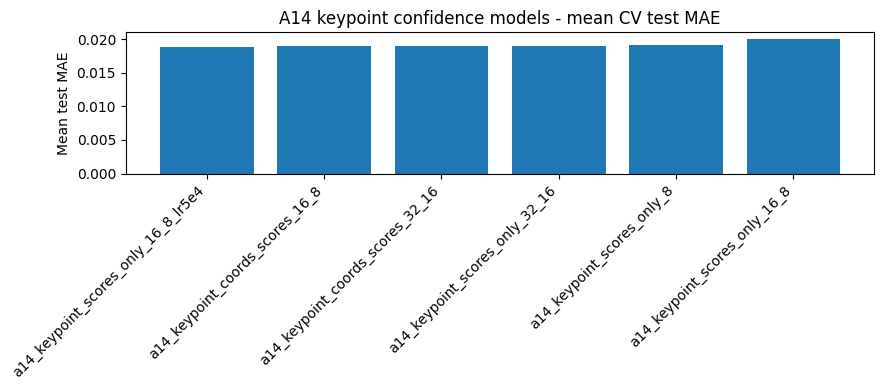

Saved: reporting\results\a14_keypoint_confidence_model_mae_comparison.png


In [24]:
plt.figure(figsize=(9, 4))
plt.bar(summary_df["run_name"], summary_df["mean_test_mae"])
plt.title("A14 keypoint confidence models - mean CV test MAE")
plt.ylabel("Mean test MAE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

mae_plot_path = output_dir / "a14_keypoint_confidence_model_mae_comparison.png"
plt.savefig(mae_plot_path, dpi=150)
plt.show()

print("Saved:", mae_plot_path)

## Select champion

The champion is selected by lowest mean test MAE.

If two models are very close, prefer the smaller one because the assignment emphasizes online decision capability.

In [25]:
best_run_name = summary_df.iloc[0]["run_name"]
best_config_name = best_run_name.replace("a14_keypoint_", "")

CHAMPION_CONFIG = None

for config in KEYPOINT_CONFIGS:
    if config["name"] == best_config_name:
        CHAMPION_CONFIG = config.copy()
        break

if CHAMPION_CONFIG is None:
    raise RuntimeError("Could not find champion config.")

print("Best run:", best_run_name)
print("Selected champion config:")
print(json.dumps(CHAMPION_CONFIG, indent=2))

Best run: a14_keypoint_scores_only_16_8_lr5e4
Selected champion config:
{
  "name": "scores_only_16_8_lr5e4",
  "seq_len": 10,
  "feature_set": "keypoint_scores",
  "hidden_dims": [
    16,
    8
  ],
  "dropout": 0.05,
  "batch_size": 16,
  "learning_rate": 0.0005,
  "epochs": 120,
  "patience": 15
}


## Train final champion on all available data

In [26]:
def train_final_model_on_all_sequences(config: dict):
    all_ids = sequence_ids_all.copy()

    train_ids, val_ids = train_test_split(
        all_ids,
        test_size=VALIDATION_SPLIT,
        random_state=RANDOM_SEED,
    )

    feature_cols = get_feature_columns(config["feature_set"])

    final_scaler = fit_feature_scaler(
        sequence_ids=train_ids,
        sequence_dfs=sequence_dfs,
        feature_cols=feature_cols,
    )

    X_train, y_train, train_ids_used = build_xy_for_sequence_ids(
        sequence_ids=train_ids,
        sequence_dfs=sequence_dfs,
        labels_lookup=labels_lookup,
        scaler=final_scaler,
        seq_len=config["seq_len"],
        feature_set=config["feature_set"],
    )

    X_val, y_val, val_ids_used = build_xy_for_sequence_ids(
        sequence_ids=val_ids,
        sequence_dfs=sequence_dfs,
        labels_lookup=labels_lookup,
        scaler=final_scaler,
        seq_len=config["seq_len"],
        feature_set=config["feature_set"],
    )

    input_dim = X_train.shape[1]

    final_model = TinyDenseKeypointConfidenceRegressor(
        input_dim=input_dim,
        hidden_dims=config["hidden_dims"],
        dropout=config["dropout"],
    ).to(DEVICE)

    train_loader = make_loader(
        X_train,
        y_train,
        batch_size=config["batch_size"],
        shuffle=True,
    )

    val_loader = make_loader(
        X_val,
        y_val,
        batch_size=config["batch_size"],
        shuffle=False,
    )

    final_model, final_history_df, final_train_summary = train_one_model(
        model=final_model,
        train_loader=train_loader,
        val_loader=val_loader,
        learning_rate=config["learning_rate"],
        epochs=config["epochs"],
        patience=config["patience"],
    )

    train_metrics = evaluate_regression_model(final_model, train_loader)
    val_metrics = evaluate_regression_model(final_model, val_loader)

    final_info = {
        "input_dim": input_dim,
        "n_parameters": count_trainable_parameters(final_model),
        "estimated_macs_per_prediction": estimate_dense_macs(input_dim, config["hidden_dims"]),
        "n_train_sequences": len(train_ids),
        "n_val_sequences": len(val_ids),
        "best_val_loss": final_train_summary["best_val_loss"],
        "best_epoch": final_train_summary["best_epoch"],
        "epochs_ran": final_train_summary["epochs_ran"],
        "train_mae": train_metrics["mae"],
        "train_mse": train_metrics["mse"],
        "train_rmse": train_metrics["rmse"],
        "train_r2": train_metrics["r2"],
        "val_mae": val_metrics["mae"],
        "val_mse": val_metrics["mse"],
        "val_rmse": val_metrics["rmse"],
        "val_r2": val_metrics["r2"],
    }

    return final_model, final_scaler, final_history_df, final_info


final_model, final_scaler, final_history_df, final_info = train_final_model_on_all_sequences(CHAMPION_CONFIG)

print("Final champion info:")
print(json.dumps(final_info, indent=2))

Final champion info:
{
  "input_dim": 130,
  "n_parameters": 2241,
  "estimated_macs_per_prediction": 2216,
  "n_train_sequences": 102,
  "n_val_sequences": 12,
  "best_val_loss": 0.00022417159925680608,
  "best_epoch": 112,
  "epochs_ran": 120,
  "train_mae": 0.01320144563328986,
  "train_mse": 0.0003021991206634419,
  "train_rmse": 0.017383875306255563,
  "train_r2": 0.6019574547554184,
  "val_mae": 0.010689583917458853,
  "val_mse": 0.0002241715874201263,
  "val_rmse": 0.014972360783127232,
  "val_r2": 0.5914621387042347
}


## MLflow pyfunc wrapper

The wrapper makes the model reusable.

It accepts a raw MoveNet dataframe and performs:

1. MoveNet-to-assignment conversion if needed
2. fixed-length first-frame selection
3. feature scaling
4. Dense model prediction
5. practical reject/warn/accept decision

In [27]:
class KeypointConfidencePredictor(mlflow.pyfunc.PythonModel):
    """
    MLflow pyfunc wrapper for A14 keypoint confidence prediction.

    Expected input to predict():
    - pandas DataFrame with one or more MoveNet sequences
    - If multiple sequences are included, a sequence_id column should be present
    - If sequence_id is missing, the whole input is treated as one sequence

    Output:
    - one row per sequence with predicted keypoint confidence and practical decision
    """

    def __init__(
        self,
        model,
        scaler,
        champion_config,
        coord_cols,
        score_cols,
        joints_13,
        movenet_to_assignment,
        accept_threshold=0.70,
        warn_threshold=0.60,
        device="cpu",
    ):
        self.model = model
        self.scaler = scaler
        self.champion_config = champion_config
        self.coord_cols = coord_cols
        self.score_cols = score_cols
        self.joints_13 = joints_13
        self.movenet_to_assignment = movenet_to_assignment
        self.accept_threshold = accept_threshold
        self.warn_threshold = warn_threshold
        self.device = device

    def _strip_columns(self, df):
        df = df.copy()
        df.columns = [str(c).strip() for c in df.columns]
        return df

    def _find_frame_col(self, df):
        frame_col_candidates = [
            "frame_index",
            "frame",
            "frame_id",
            "Frame",
            "FrameID",
            "FrameNo",
            "frame_no",
            "image_id",
            "image_index",
        ]

        for col in frame_col_candidates:
            if col in df.columns:
                return col

        raise ValueError(
            f"Could not find a frame column. Available columns: {df.columns.tolist()}"
        )

    def _movenet_as_assignment(self, df):
        df = self._strip_columns(df)

        required_cols = set(self.coord_cols + self.score_cols)

        if required_cols.issubset(set(df.columns)):
            out = df.copy()

            if "frame_index" not in out.columns:
                frame_col = self._find_frame_col(out)
                out["frame_index"] = pd.to_numeric(out[frame_col], errors="coerce").astype(int)

            return out.sort_values("frame_index").reset_index(drop=True)

        frame_col = self._find_frame_col(df)

        out = pd.DataFrame()
        out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

        for movenet_joint, assignment_joint in self.movenet_to_assignment.items():
            for suffix in ["x", "y", "score"]:
                src = f"{movenet_joint}_{suffix}"
                dst = f"{assignment_joint}_{suffix}"

                if src in df.columns:
                    out[dst] = pd.to_numeric(df[src], errors="coerce")
                elif dst in df.columns:
                    out[dst] = pd.to_numeric(df[dst], errors="coerce")
                else:
                    raise ValueError(f"Missing required column: {src} or {dst}")

        out = out.sort_values("frame_index").reset_index(drop=True)
        return out

    def _get_feature_columns(self):
        feature_set = self.champion_config["feature_set"]

        if feature_set == "keypoint_scores":
            return self.score_cols

        if feature_set == "coords_keypoint_scores":
            return self.coord_cols + self.score_cols

        raise ValueError(f"Unknown feature_set: {feature_set}")

    def _sequence_to_vector(self, df):
        seq_len = self.champion_config["seq_len"]
        feature_cols = self._get_feature_columns()

        if len(df) < seq_len:
            raise ValueError(
                f"Sequence has {len(df)} frames, but model requires at least {seq_len} frames."
            )

        first_df = df.iloc[:seq_len].copy().reset_index(drop=True)
        values_df = first_df[feature_cols].copy()

        values = self.scaler.transform(values_df)
        return values.astype(np.float32).reshape(1, -1)

    def _decision_from_score(self, score):
        if score >= self.accept_threshold:
            return "accept"
        if score >= self.warn_threshold:
            return "warn"
        return "reject"

    def predict(self, context, model_input):
        df = model_input.copy()

        if "sequence_id" not in df.columns:
            df["sequence_id"] = "sequence_0"

        rows = []

        self.model.eval()
        self.model.to(self.device)

        for sequence_id, group_df in df.groupby("sequence_id"):
            seq_df = self._movenet_as_assignment(group_df)
            x_vec = self._sequence_to_vector(seq_df)

            x_tensor = torch.tensor(x_vec, dtype=torch.float32).to(self.device)

            with torch.no_grad():
                pred_score = self.model(x_tensor).detach().cpu().numpy()[0]

            pred_score = float(pred_score)

            rows.append({
                "sequence_id": sequence_id,
                "predicted_keypoint_confidence": pred_score,
                "decision": self._decision_from_score(pred_score),
                "accept_threshold": self.accept_threshold,
                "warn_threshold": self.warn_threshold,
            })

        return pd.DataFrame(rows)


final_wrapped_keypoint_model = KeypointConfidencePredictor(
    model=final_model.cpu(),
    scaler=final_scaler,
    champion_config=CHAMPION_CONFIG,
    coord_cols=COORD_COLS,
    score_cols=SCORE_COLS,
    joints_13=JOINTS_13,
    movenet_to_assignment=MOVENET_TO_ASSIGNMENT,
    accept_threshold=KEYPOINT_CONFIDENCE_ACCEPT_THRESHOLD,
    warn_threshold=KEYPOINT_CONFIDENCE_WARN_THRESHOLD,
    device="cpu",
)

c:\Users\Kim\software engineering\year 4\LP3\4DT907\machine_learning_project_4dt907\.venv\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


## Save and log final model to MLflow

In [28]:
final_model_path = artifact_dir / "a14_keypoint_confidence_champion_model.pt"
final_scaler_path = artifact_dir / "a14_keypoint_confidence_scaler.joblib"
final_config_path = artifact_dir / "a14_keypoint_confidence_champion_config.json"
final_history_path = output_dir / "a14_keypoint_confidence_champion_training_history.csv"

torch.save(final_model.cpu().state_dict(), final_model_path)
joblib.dump(final_scaler, final_scaler_path)
final_history_df.to_csv(final_history_path, index=False)

final_config_to_save = {
    **CHAMPION_CONFIG,
    "input_dim": final_info["input_dim"],
    "n_parameters": final_info["n_parameters"],
    "estimated_macs_per_prediction": final_info["estimated_macs_per_prediction"],
    "coord_cols": COORD_COLS,
    "score_cols": SCORE_COLS,
    "joints_13": JOINTS_13,
    "target": "mean_keypoint_confidence_whole_recording",
    "accept_threshold": KEYPOINT_CONFIDENCE_ACCEPT_THRESHOLD,
    "warn_threshold": KEYPOINT_CONFIDENCE_WARN_THRESHOLD,
    "normalization": "MinMaxScaler fit on training data only",
}

with open(final_config_path, "w") as f:
    json.dump(final_config_to_save, f, indent=2)

example_sequence_id = sequence_ids_all[0]
example_raw_df = pd.read_csv(kept_catalog_df.loc[kept_catalog_df["sequence_id"] == example_sequence_id, "path"].iloc[0])
example_raw_df["sequence_id"] = example_sequence_id

with mlflow.start_run(run_name=f"a14_logged_keypoint_confidence_champion_{CHAMPION_CONFIG['name']}"):
    mlflow.log_param("task", "ugly_recording_keypoint_confidence_regression")
    mlflow.log_param("input_type", "MoveNet_keypoint_scores")
    mlflow.log_param("model_family", "TinyDense")
    mlflow.log_param("target", "mean_keypoint_confidence_whole_recording")
    mlflow.log_param("seq_len", CHAMPION_CONFIG["seq_len"])
    mlflow.log_param("feature_set", CHAMPION_CONFIG["feature_set"])
    mlflow.log_param("hidden_dims", str(CHAMPION_CONFIG["hidden_dims"]))
    mlflow.log_param("dropout", CHAMPION_CONFIG["dropout"])
    mlflow.log_param("batch_size", CHAMPION_CONFIG["batch_size"])
    mlflow.log_param("learning_rate", CHAMPION_CONFIG["learning_rate"])
    mlflow.log_param("epochs", CHAMPION_CONFIG["epochs"])
    mlflow.log_param("patience", CHAMPION_CONFIG["patience"])
    mlflow.log_param("input_dim", final_info["input_dim"])
    mlflow.log_param("n_parameters", final_info["n_parameters"])
    mlflow.log_param("estimated_macs_per_prediction", final_info["estimated_macs_per_prediction"])
    mlflow.log_param("accept_threshold", KEYPOINT_CONFIDENCE_ACCEPT_THRESHOLD)
    mlflow.log_param("warn_threshold", KEYPOINT_CONFIDENCE_WARN_THRESHOLD)
    mlflow.log_param("online_decision", True)
    mlflow.log_param("uses_only_first_frames", True)

    for key, value in final_info.items():
        mlflow.log_metric(key, float(value))

    mlflow.log_artifact(str(final_model_path))
    mlflow.log_artifact(str(final_scaler_path))
    mlflow.log_artifact(str(final_config_path))
    mlflow.log_artifact(str(final_history_path))
    mlflow.log_artifact(str(catalog_path))
    mlflow.log_artifact(str(summary_path))

    mlflow.pyfunc.log_model(
        name="model",
        python_model=final_wrapped_keypoint_model,
        input_example=example_raw_df.head(CHAMPION_CONFIG["seq_len"]),
    )

    logged_run_id = mlflow.active_run().info.run_id
    logged_model_uri = f"runs:/{logged_run_id}/model"

print("Logged final keypoint confidence model.")
print("Run ID:", logged_run_id)
print("Model URI:", logged_model_uri)

2026/05/15 11:44:39 INFO mlflow.pyfunc: Inferring model signature from input example
2026/05/15 11:44:48 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


🏃 View run a14_logged_keypoint_confidence_champion_scores_only_16_8_lr5e4 at: https://172.27.62.170:5001/#/experiments/33/runs/729c11e0c12941b7a31e2c939884333b
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/33
Logged final keypoint confidence model.
Run ID: 729c11e0c12941b7a31e2c939884333b
Model URI: runs:/729c11e0c12941b7a31e2c939884333b/model


## Practical usefulness check

The model returns:

- predicted keypoint confidence score
- practical decision: accept, warn, or reject

Suggested interpretation:

- `accept`: continue processing the recording
- `warn`: the recording may be unstable; ask the user to improve lighting/background/position
- `reject`: recording is likely too ugly to process reliably

The thresholds are not final. They should be discussed together with the pose-confidence score and the manual good/bad/ugly labels.

In [29]:
loaded_keypoint_model = mlflow.pyfunc.load_model(logged_model_uri)

example_prediction = loaded_keypoint_model.predict(example_raw_df)

print("Example sequence:", example_sequence_id)
display(example_prediction)

true_score = labels_lookup[example_sequence_id]
pred_score = example_prediction["predicted_keypoint_confidence"].iloc[0]

print("True whole-recording keypoint confidence:", true_score)
print("Predicted from first frames:", pred_score)
print("Absolute error:", abs(true_score - pred_score))

Example sequence: A1


,sequence_id,predicted_keypoint_confidence,decision,accept_threshold,warn_threshold
0,A1,0.535317,reject,0.7,0.6


True whole-recording keypoint confidence: 0.5893412828445435
Predicted from first frames: 0.5353169441223145
Absolute error: 0.054024338722229004


In [30]:
def predict_all_sequences_with_logged_model(model_uri: str) -> pd.DataFrame:
    loaded_model = mlflow.pyfunc.load_model(model_uri)

    rows = []

    for _, row in kept_catalog_df.iterrows():
        sequence_id = row["sequence_id"]
        path = row["path"]

        raw_df = pd.read_csv(path)
        raw_df["sequence_id"] = sequence_id

        pred_df = loaded_model.predict(raw_df)

        rows.append({
            "sequence_id": sequence_id,
            "true_keypoint_confidence": row["target_keypoint_confidence"],
            "predicted_keypoint_confidence": pred_df["predicted_keypoint_confidence"].iloc[0],
            "decision": pred_df["decision"].iloc[0],
            "absolute_error": abs(
                row["target_keypoint_confidence"] - pred_df["predicted_keypoint_confidence"].iloc[0]
            ),
        })

    return pd.DataFrame(rows)


practical_eval_df = predict_all_sequences_with_logged_model(logged_model_uri)

practical_eval_path = output_dir / "a14_keypoint_confidence_practical_eval_logged_model.csv"
practical_eval_df.to_csv(practical_eval_path, index=False)

display(practical_eval_df.head())
display(practical_eval_df["decision"].value_counts().to_frame("count"))

print("Mean absolute error on all available recordings:")
print(practical_eval_df["absolute_error"].mean())

print("Saved:", practical_eval_path)

,sequence_id,true_keypoint_confidence,predicted_keypoint_confidence,decision,absolute_error
0,A1,0.589341,0.535317,reject,0.054024
1,G01,0.546313,0.512173,reject,0.034141
2,G02,0.554782,0.529365,reject,0.025416
3,G03,0.547615,0.531794,reject,0.015822
4,G04,0.493673,0.533310,reject,0.039637


,count
decision,
reject,114


Mean absolute error on all available recordings:
0.012937036784071671
Saved: reporting\results\a14_keypoint_confidence_practical_eval_logged_model.csv


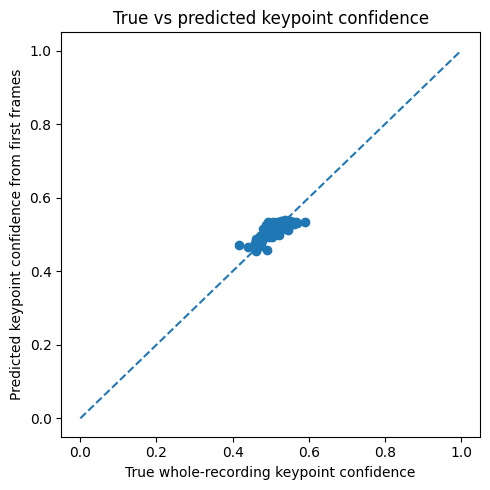

Saved: reporting\results\a14_keypoint_confidence_true_vs_predicted.png


In [31]:
plt.figure(figsize=(5, 5))
plt.scatter(
    practical_eval_df["true_keypoint_confidence"],
    practical_eval_df["predicted_keypoint_confidence"],
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("True vs predicted keypoint confidence")
plt.xlabel("True whole-recording keypoint confidence")
plt.ylabel("Predicted keypoint confidence from first frames")
plt.tight_layout()

scatter_path = output_dir / "a14_keypoint_confidence_true_vs_predicted.png"
plt.savefig(scatter_path, dpi=150)
plt.show()

print("Saved:", scatter_path)

## Manual good/bad/ugly label template for group cross-labeling

The objective keypoint confidence score is only one part of A14.

The assignment also asks the group to define labeling criteria and share the labels.

Use the template below for manual cross-labeling.

Suggested manual scale:

- `5 = good recording`: skeleton stable, joints mostly correct, little/no flickering
- `4 = acceptable recording`: minor issues but usable
- `3 = borderline recording`: visible instability but may still be usable
- `2 = bad/ugly recording`: several wrong joints or frequent flickering
- `1 = very ugly recording`: unusable skeleton, severe joint errors or flickering

Each group member should label the same subset of recordings.  
Then compare labels and settle on criteria that maximize inter-rater agreement.

In [32]:
manual_label_template_df = kept_catalog_df[
    [
        "sequence_id",
        "path",
        "n_frames",
        "target_keypoint_confidence",
        "min_keypoint_confidence",
        "p10_keypoint_confidence",
        "fraction_keypoints_below_030",
        "fraction_frames_with_any_keypoint_below_030",
    ]
].copy()

manual_label_template_df["manual_goodness_score_1_to_5"] = ""
manual_label_template_df["manual_label_good_bad_ugly"] = ""
manual_label_template_df["rater_name"] = ""
manual_label_template_df["comment"] = ""

manual_label_template_path = output_dir / "a14_manual_good_bad_ugly_label_template.csv"
manual_label_template_df.to_csv(manual_label_template_path, index=False)

display(manual_label_template_df.head())

print("Saved manual label template:")
print(manual_label_template_path)

,sequence_id,path,n_frames,target_keypoint_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030,manual_goodness_score_1_to_5,manual_label_good_bad_ugly,rater_name,comment
0,A1,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,229,0.589341,0.1516,0.41990,0.012429,0.148472,,,,
1,G01,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,254,0.546313,0.1342,0.36831,0.039976,0.401575,,,,
2,G02,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,314,0.554782,0.0511,0.37742,0.050710,0.423567,,,,
3,G03,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,250,0.547615,0.0435,0.35049,0.063692,0.420000,,,,
4,G04,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,219,0.493673,0.0232,0.21594,0.154197,0.666667,,,,


Saved manual label template:
reporting\results\a14_manual_good_bad_ugly_label_template.csv


## Conclusion draft

This notebook implemented the keypoint-confidence part of A14.

### Deep Learning steps

The notebook followed the required Deep Learning steps:

1. Loaded MoveNet recordings.
2. Extracted 13 keypoint confidence scores per frame.
3. Calculated an objective whole-recording keypoint confidence score.
4. Used only the first `c` frames as input to support early online decisions.
5. Trained small Dense regression models.
6. Evaluated MAE, MSE, RMSE, R², parameter count, estimated operations, and prediction time.
7. Logged the final champion model to MLflow with a reusable pyfunc wrapper.

### Objective labeling

The objective target was:

`target_keypoint_confidence = mean confidence across all selected keypoints and all frames`

This label is objective and reproducible because it is calculated directly from the MoveNet keypoint confidence scores.

A manual good/bad/ugly label template was also created for the group’s subjective cross-labeling work.

### Practical application context

The model predicts the expected keypoint confidence of the whole recording from only the first frames.

This is useful because the system can warn or reject recordings early, before running the complete exercise pipeline.

The final decision should later combine:

- this keypoint-confidence predictor
- the pose-confidence predictor from the other implementation
- the group’s manual good/bad/ugly criteria